In [1]:
# 1C. Build Feedforward Neural Network (FNN) with Keras and TensorFlow for 
# classification of CIFAR10 image dataset using the following steps: 
# a. Import the necessary packages 
# b. Load the training and testing data 
# c. Define the network architecture using Keras 
# d. Train the model using SGD/Adam optimizer 
# e. Evaluate the network 
# f. Plot the training loss and accuracy 

In [11]:
# a. Import the necessary packages 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split

In [7]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers  import Input,Flatten,Dense
from tensorflow.keras.optimizers import SGD

In [8]:
# b. Load the training and testing data 

In [9]:
data = pd.read_csv('./LP IV Updated Datasets/FNN and CNN/CIFAR10/cifar-10.csv')

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,145,151,156,155,153,153,157,161,161,161,...,68,64,61,63,59,57,56,53,54,2
49996,255,254,255,254,254,254,254,253,254,254,...,61,64,68,64,76,82,79,81,76,6
49997,35,40,42,39,43,45,48,51,53,56,...,94,104,103,96,93,87,77,66,50,9
49998,189,186,185,184,182,181,180,180,181,180,...,166,171,171,172,169,165,169,171,171,1


In [12]:
#  separate out the x and y 
x = data.iloc[: , :-1].values
y = data.iloc[ : , -1 ].values

In [13]:
#traim test split 
x_train , x_test , y_train ,y_test = train_test_split(x , y , test_size=0.2 ,random_state=42)

In [18]:
#normalize the data 
print("Training  data : " ,x_train.shape )
print("Testing data : " , x_test.shape)
print( )
x_test  = x_test / 255.0
x_train = x_train  / 255.0

Training  data :  (40000, 3072)
Testing data :  (10000, 3072)



In [19]:
# c. Define the network architecture using Keras 
model = Sequential([
    Input(shape=(3072,)) , 
    Flatten(),
    Dense( 128 , activation='relu'),
    Dense(64 , activation='relu'),
    Dense( 10 , activation='softmax')
])

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 402,250 (1.53 MB)

 Trainable params: 402,250 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# d. Train the model using SGD/Adam optimizer 
model.compile(
    optimizer = SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [26]:
history = model.fit(
    x_train , 
    y_train , 
    epochs=11,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.0982 - loss: 2.3027 - val_accuracy: 0.1001 - val_loss: 2.3027
Epoch 2/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.1005 - loss: 2.3027 - val_accuracy: 0.1006 - val_loss: 2.3027
Epoch 3/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.0988 - loss: 2.3027 - val_accuracy: 0.1019 - val_loss: 2.3027
Epoch 4/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.1008 - loss: 2.3027 - val_accuracy: 0.1019 - val_loss: 2.3027
Epoch 5/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.0993 - loss: 2.3027 - val_accuracy: 0.1019 - val_loss: 2.3027
Epoch 6/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.0984 - loss: 2.3027 - val_accuracy: 0.1006 - val_loss: 2.3027
Epoch 7/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.1009 - loss: 2.3027 - val_accuracy: 0.1019 - val_loss: 2.3027
Epoch 8/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.0996 - loss: 2.3027 - 

In [27]:
# e. Evaluate the network 
test_loss , test_accuracy = model.evaluate( x_test , y_test)
print("Test Loss : " , test_loss)
print(" Test Accuracy : " , test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.0933 - loss: 2.3028
Test Loss :  2.3028335571289062
 Test Accuracy :  0.093299999833107


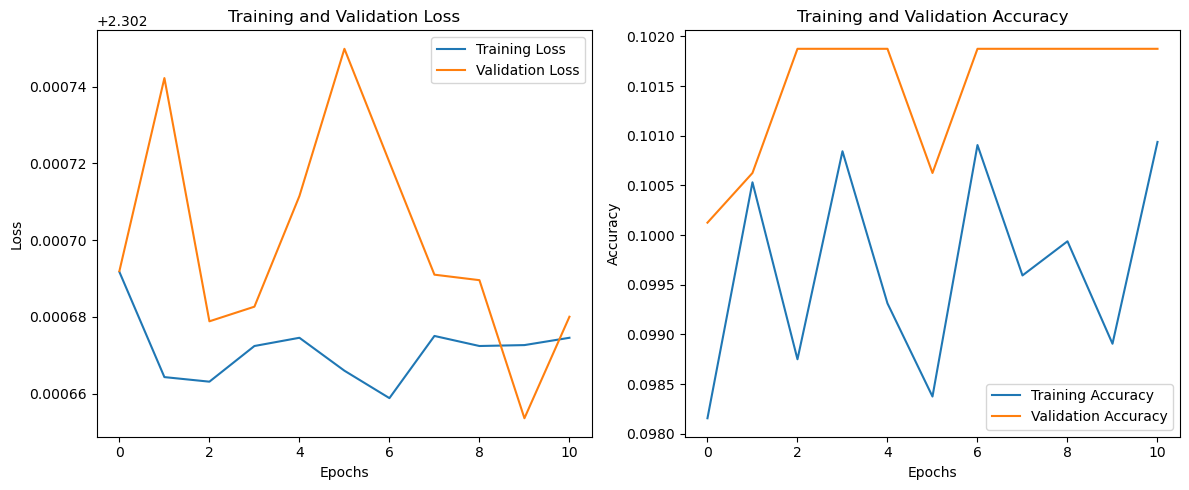

In [28]:
# 8. Plot training loss and accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

